In [ ]:
!pip install ultralytics==8.4.170

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="Ww3VG35l6tIiziBR2gr0")
project = rf.workspace("karen-cardona-gutierrez").project("identimar-rayas")
version = project.version(2)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 55.1 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to IdentiMar-Rayas-2 in yolov8:: 100%|██████████| 1373/1373 [00:00<00:00, 8451.34it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
import torch
print("GPU disponible:", torch.cuda.is_available())
print("Nombre GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "ninguna")

GPU disponible: True
Nombre GPU: Tesla T4


Sobremuestreo (oversampling)

In [ ]:
import zipfile
import os

# Rutas posibles para el archivo zip
rutas_posibles = [
    '/content/IdentiMar-Rayas-2/identimar-vision (1).zip',
    '/content/drive/MyDrive/identimar-vision (1).zip'
]

zip_encontrado = None
for ruta in rutas_posibles:
    if os.path.exists(ruta):
        zip_encontrado = ruta
        break

if zip_encontrado:
    destino = '/content/identimar_vision_extracted'
    with zipfile.ZipFile(zip_encontrado, 'r') as zip_ref:
        zip_ref.extractall(destino)
    print(f"¡Éxito! Archivo extraído en: {destino}")

    # Buscar si el archivo sobremuestreo_idempotente.py está en la extracción
    encontrado = False
    for root, dirs, files in os.walk(destino):
        if 'sobremuestreo_idempotente.py' in files:
            print(f"\n¡Encontrado! El archivo se encuentra en: {root}")
            # Agregar la ruta encontrada al sys.path para que puedas importarlo
            import sys
            if root not in sys.path:
                sys.path.append(root)
                print(f"Se ha agregado '{root}' a sys.path")
            encontrado = True
            break
    if not encontrado:
        print("\nEl archivo zip fue extraído, pero no se encontró 'sobremuestreo_idempotente.py' adentro.")
else:
    print("No se encontró el archivo 'identimar-vision (1).zip'. Por favor, asegúrate de subirlo a tu entorno de Colab.")

¡Éxito! Archivo extraído en: /content/identimar_vision_extracted

¡Encontrado! El archivo se encuentra en: /content/identimar_vision_extracted/identimar-vision/entrenamiento
Se ha agregado '/content/identimar_vision_extracted/identimar-vision/entrenamiento' a sys.path


In [ ]:
import sys
sys.path.append('/content/IdentiMar-Rayas-2')

from sobremuestreo_idempotente import sobremuestreo_clase

# Ejecutar el sobremuestreo
sobremuestreo_clase(dataset.location, "Potamotrygon_magdalenae", n_copias=3)

Clase Potamotrygon_magdalenae (id 2)
  copias previas eliminadas : 0
  imágenes en train ANTES   : 597
  originales con la clase   : 93  (x3 copias)
  imágenes en train DESPUÉS : 876


{'clase': 'Potamotrygon_magdalenae',
 'id_clase': 2,
 'copias_previas_eliminadas': 0,
 'train_antes': 597,
 'originales_con_la_clase': 93,
 'n_copias': 3,
 'train_despues': 876}

Entrenar el modelo base (YOLOv8n)

In [ ]:
from ultralytics import YOLO

# Cargar el modelo preentrenado (nano) - esto YA es transferencia de aprendizaje
modelo_base = YOLO("yolov8n.pt")

# Entrenar con su dataset (dataset.location viene de la celda donde descargaron de Roboflow)
resultados_base = modelo_base.train(
    data=f"{dataset.location}/data.yaml",
    seed = 0,
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,          # detiene el entrenamiento si no mejora en 20 épocas
    project="identimar",
    name="baseline_n"
)

New https://pypi.org/project/ultralytics/8.4.177 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.170 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/IdentiMar-Rayas-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, 

Métricas del baseline

In [ ]:
# Validar sobre el set de prueba (test), no solo el de validación usado durante el entrenamiento
metricas_base = modelo_base.val(
    data=f"{dataset.location}/data.yaml",
    split="test"
)

print("Precisión promedio (mAP50):", metricas_base.box.map50)
print("Precisión promedio (mAP50-95):", metricas_base.box.map)

Ultralytics 8.4.170 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1009.1±616.5 MB/s, size: 48.0 KB)
val: Scanning /content/IdentiMar-Rayas-2/test/labels... 29 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 29/29 1.1Kit/s 0.0s
val: New cache created: /content/IdentiMar-Rayas-2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.6it/s 1.3s
                   all         29         29      0.847      0.956       0.95      0.759
    Aetobatus_narinari          8          8      0.741      0.875      0.875      0.722
      Hypanus_guttatus          8          8      0.847          1      0.967      0.749
Potamotrygon_magdalenae          5          5      0.825      0.948      0.962      0.693
   Styracura_schmardae          8          8      0.978          1    

Ver la matriz de confusión y las curvas

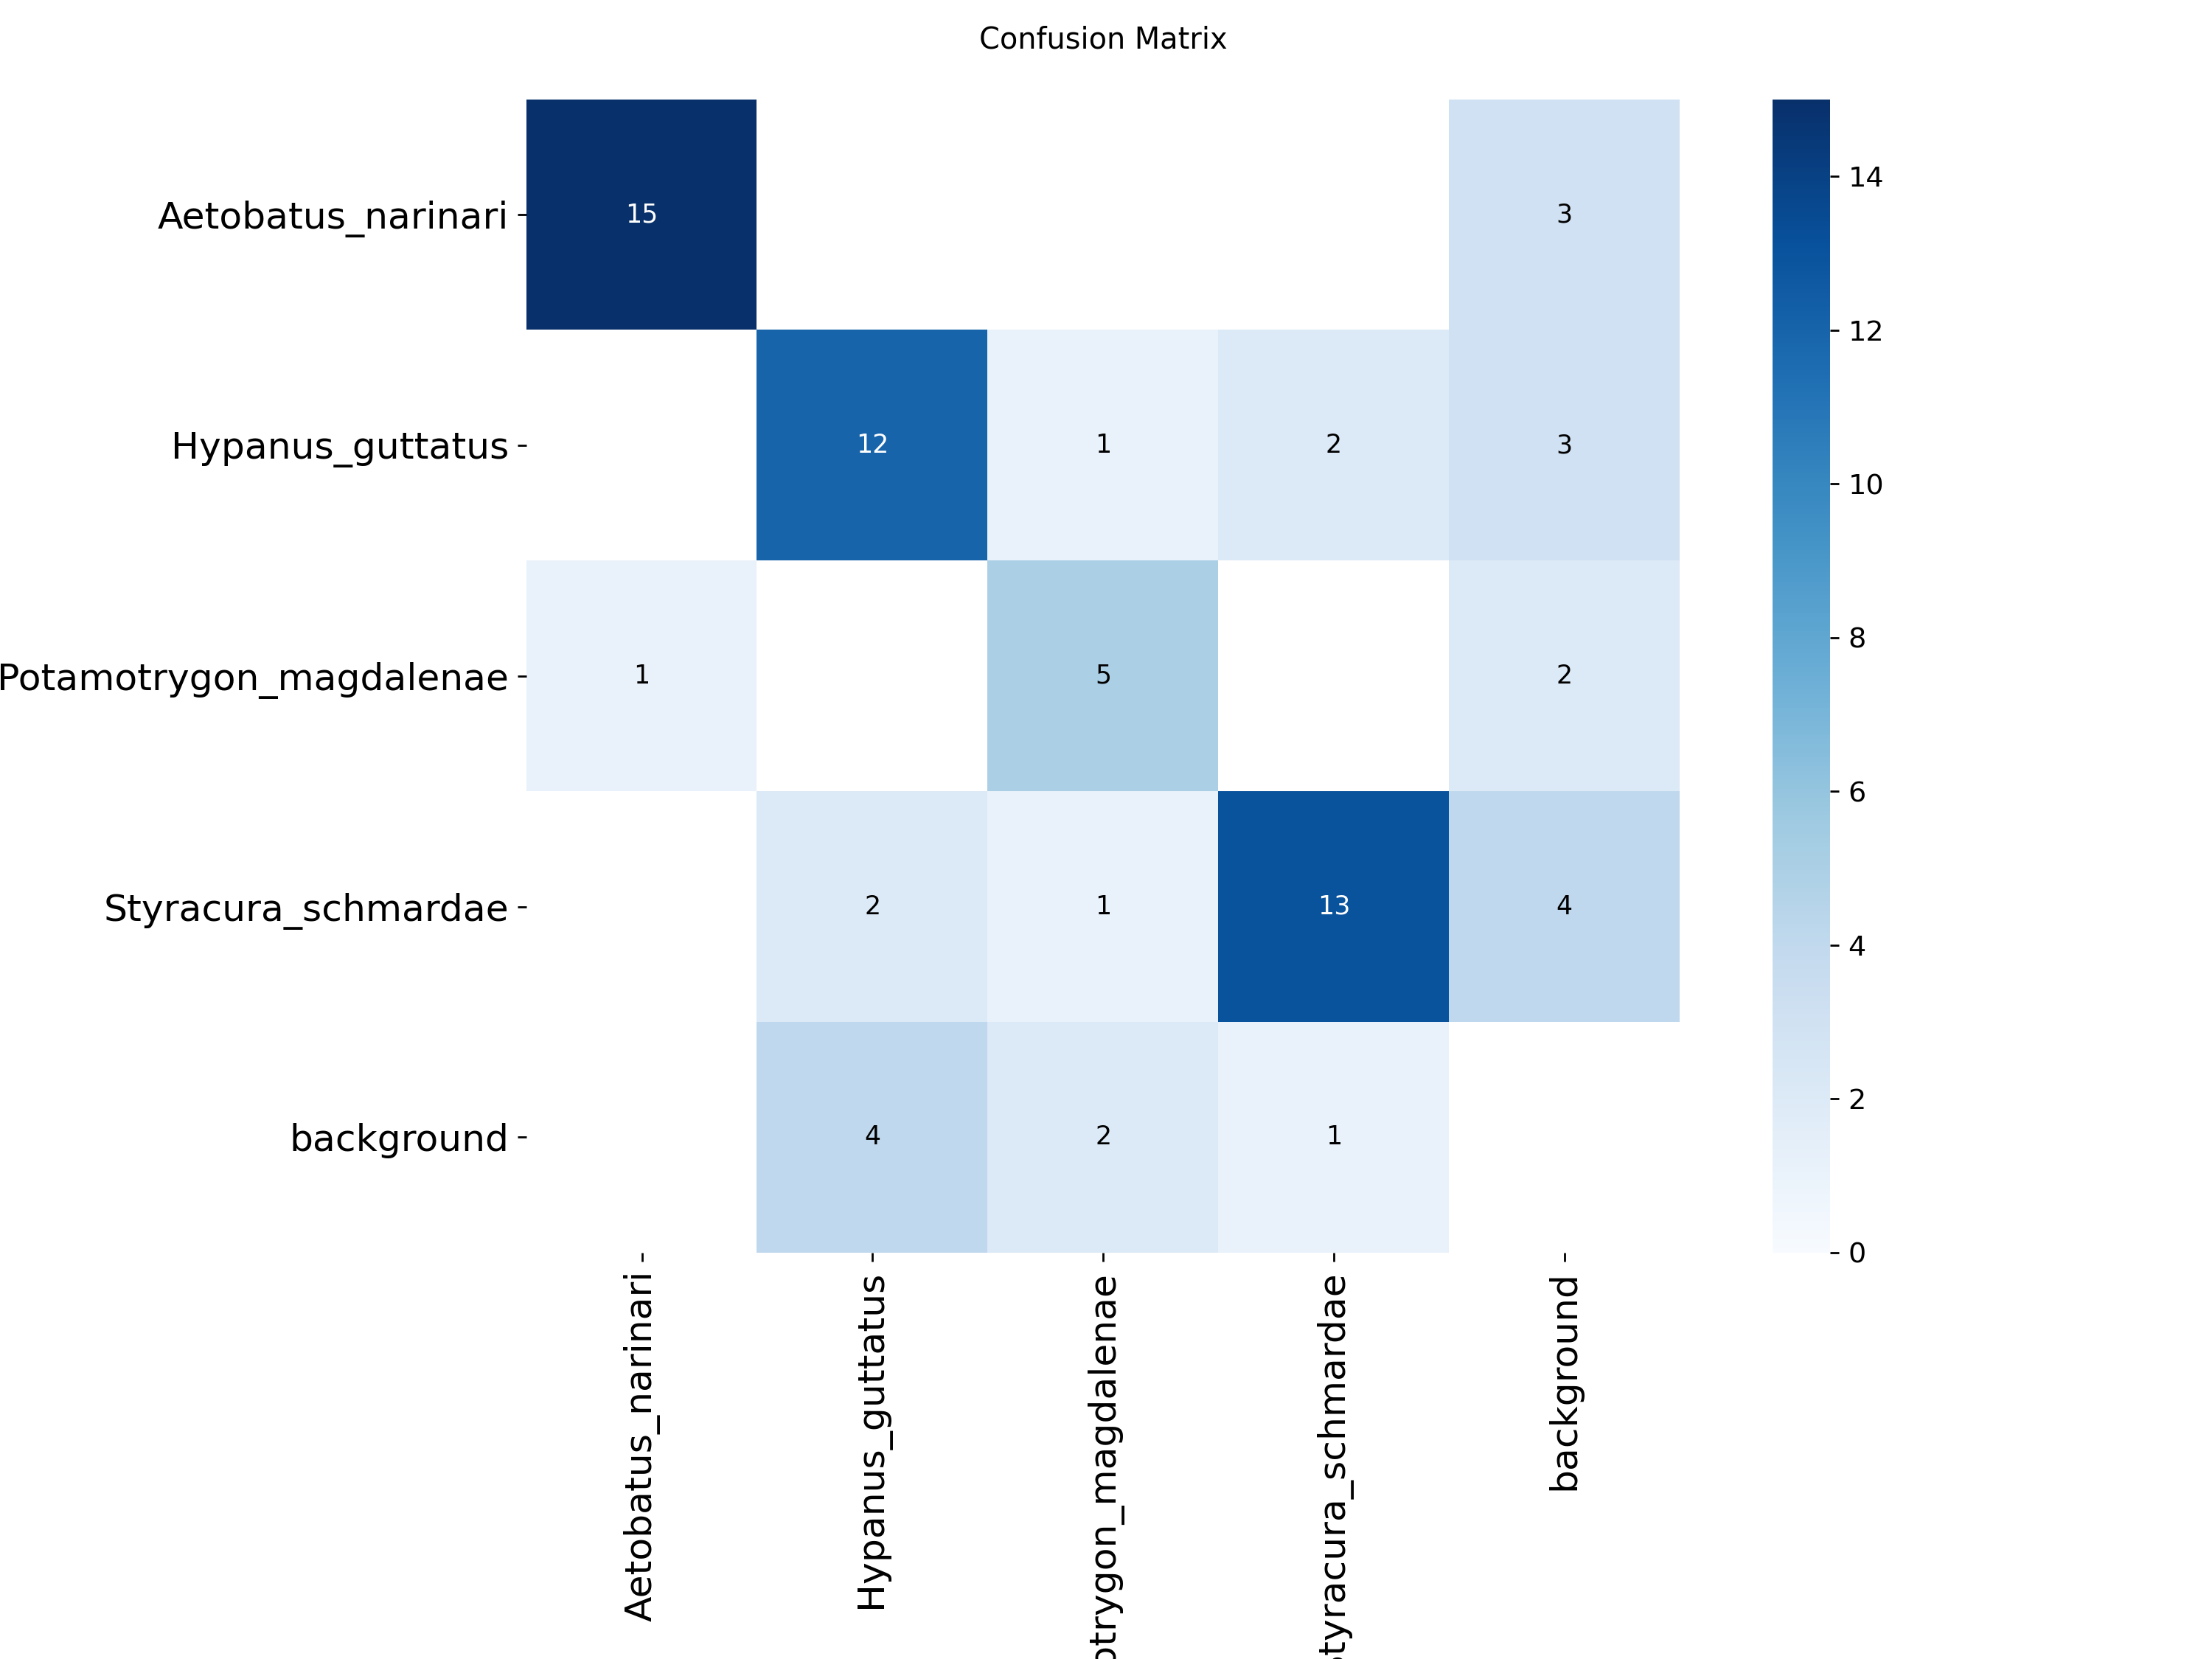

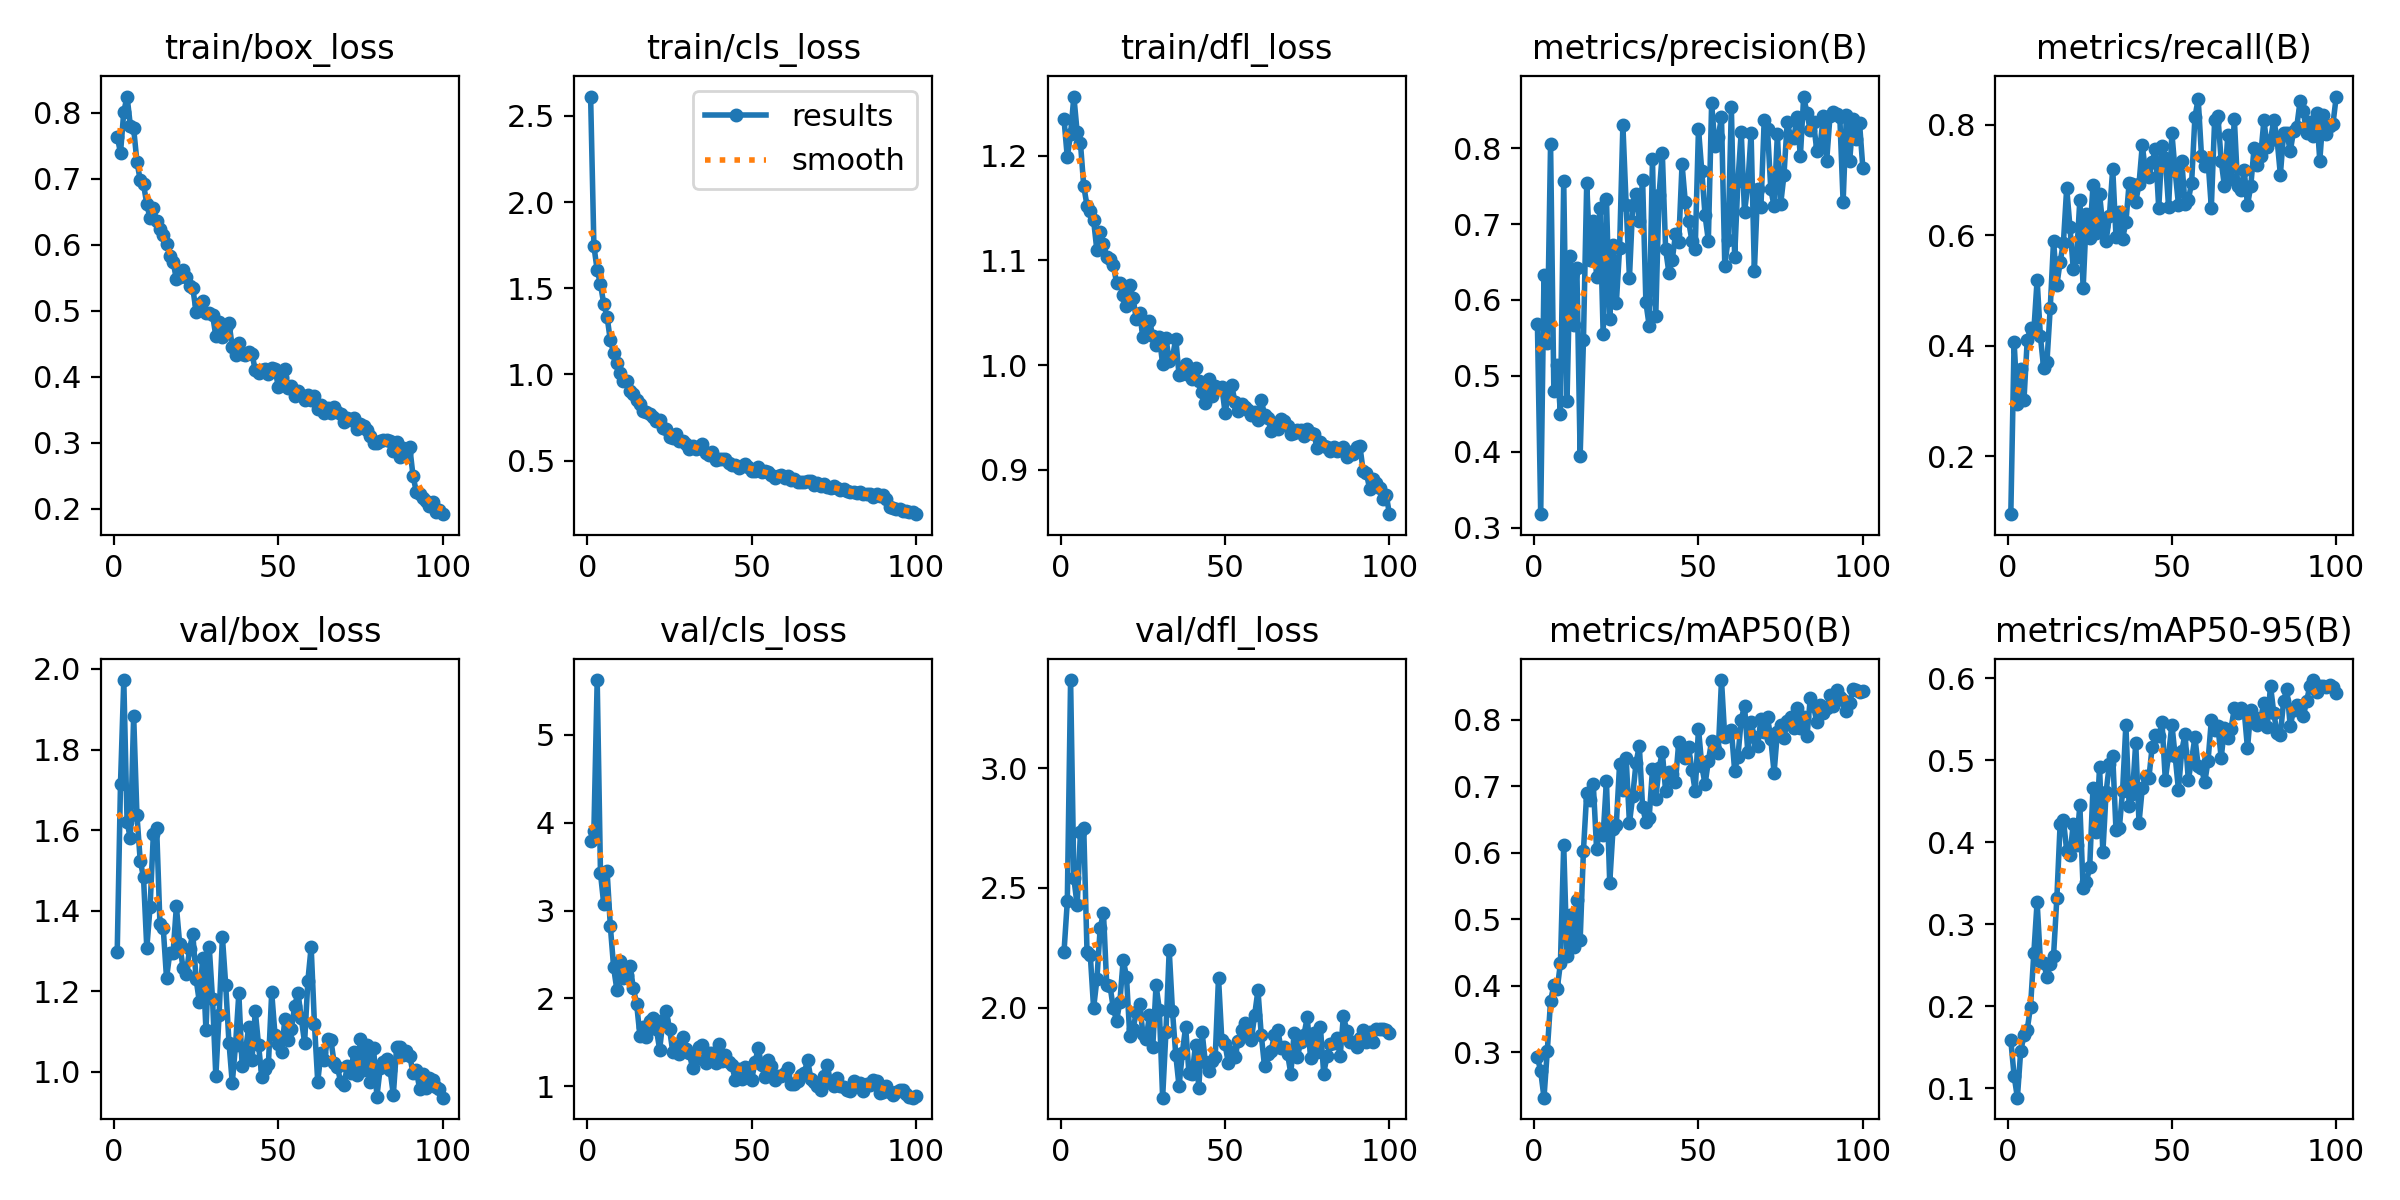

In [ ]:
from IPython.display import Image, display

display(Image(filename="/content/runs/detect/identimar/baseline_n/confusion_matrix.png"))
display(Image(filename="/content/runs/detect/identimar/baseline_n/results.png"))  # curvas de precisión, recall, F1 por época

aislar solo las imágenes problemática

2 imágenes problemáticas encontradas

IMG-0245_jpg.rf.e40db06ddefc120194779adbb68448ad.jpg - FALSA ALARMA (dijo látigo, no había)


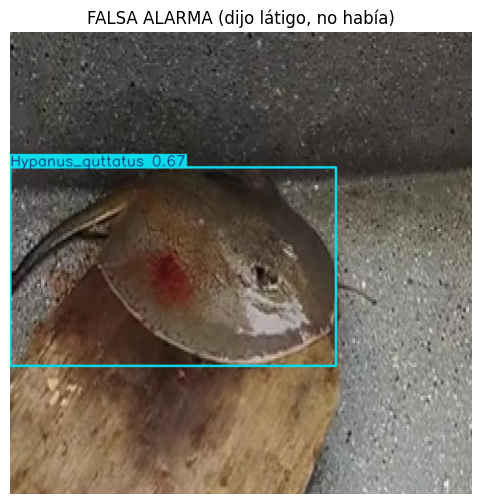

IMG-0138_jpeg.rf.db2c9d36f91d721e8a52fb26be472fd7.jpg - FALSA ALARMA (dijo látigo, no había)


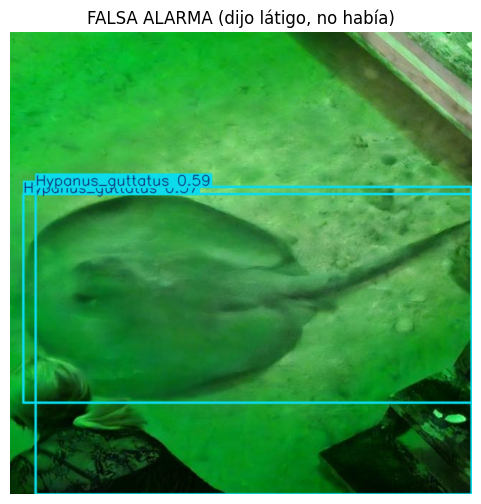

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO("/content/runs/detect/identimar/baseline_n/weights/best.pt")

val_images_dir = f"{dataset.location}/test/images"
val_labels_dir = f"{dataset.location}/test/labels"

class_names = model.names  # ej. {0: 'Aetobatus_narinari', 1: 'Hypanus_guttatus', ...}
hypanus_id = [k for k, v in class_names.items() if v == "Hypanus_guttatus"][0]

problematicas = []

for img_file in os.listdir(val_images_dir):
    if not img_file.lower().endswith((".jpg", ".jpeg", ".png")):
        continue
    img_path = os.path.join(val_images_dir, img_file)
    label_path = os.path.join(val_labels_dir, os.path.splitext(img_file)[0] + ".txt")

    # Clases reales según el archivo de etiquetas
    reales = set()
    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                reales.add(int(line.split()[0]))

    resultado = model.predict(img_path, conf=0.25, verbose=False)[0]
    predichas = set(int(c) for c in resultado.boxes.cls.tolist()) if len(resultado.boxes) else set()

    real_tiene = hypanus_id in reales
    predijo_tiene = hypanus_id in predichas

    if predijo_tiene != real_tiene:
        tipo = "FALSA ALARMA (dijo látigo, no había)" if predijo_tiene else "PERDIDA (había látigo, no la vio)"
        problematicas.append((img_path, tipo, resultado))

print(f"{len(problematicas)} imágenes problemáticas encontradas\n")

for img_path, tipo, resultado in problematicas:
    print(os.path.basename(img_path), "-", tipo)
    dibujada = cv2.cvtColor(resultado.plot(), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(6, 6))
    plt.imshow(dibujada)
    plt.axis("off")
    plt.title(tipo)
    plt.show()

4 de las 9 imágenes de Magdalena fallaron en validación

IMG-0253_jpeg.rf.dac368475328c67fd59bccfd1081178c.jpg - CONFUNDIDA con ['Hypanus_guttatus', 'Styracura_schmardae']


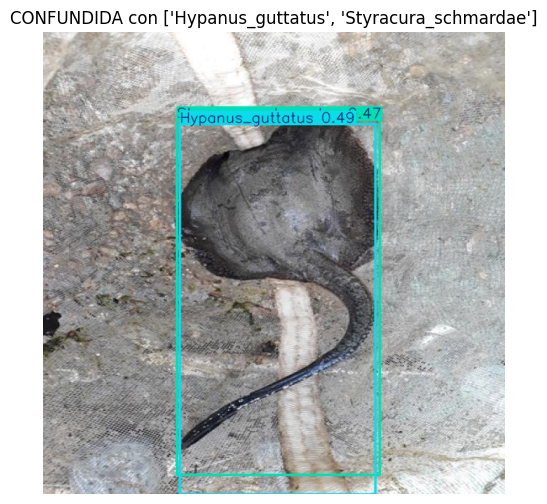

IMG-0261_jpeg.rf.fae2fd9231eda0319bc4dabd4dca8e8f.jpg - CONFUNDIDA con ['Hypanus_guttatus']


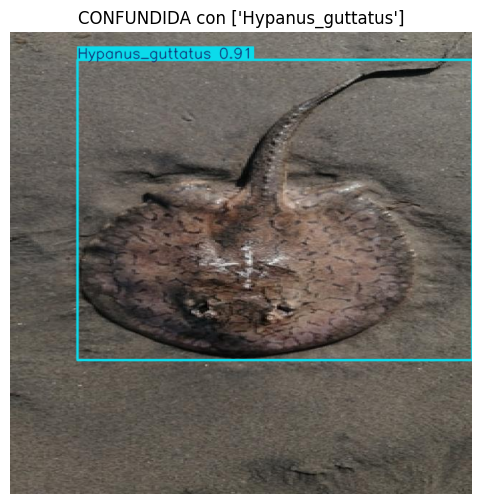

IMG-0260_jpg.rf.8810739cf684a5cb524821dd43bbb0f8.jpg - PERDIDA (no la detectó)


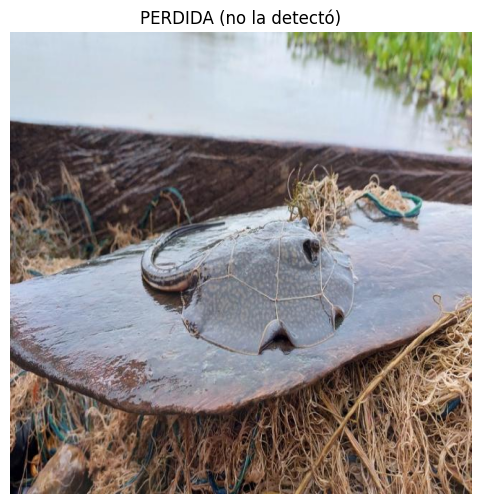

IMG-0243_jpg.rf.53c3f569598adbbec290392913db76b9.jpg - PERDIDA (no la detectó)


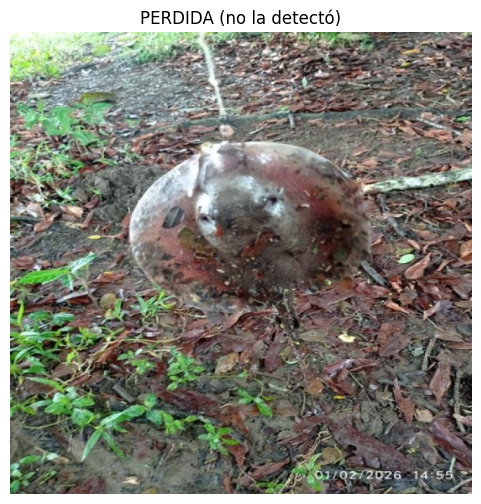

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Ajusten esta ruta a la carpeta de su último entrenamiento (el del sobremuestreo)
model = YOLO("/content/runs/detect/identimar/baseline_n/weights/best.pt")

val_images_dir = f"{dataset.location}/valid/images"
val_labels_dir = f"{dataset.location}/valid/labels"

class_names = model.names
magdalena_id = [k for k, v in class_names.items() if v == "Potamotrygon_magdalenae"][0]

problematicas = []

for img_file in os.listdir(val_images_dir):
    if not img_file.lower().endswith((".jpg", ".jpeg", ".png")):
        continue
    img_path = os.path.join(val_images_dir, img_file)
    label_path = os.path.join(val_labels_dir, os.path.splitext(img_file)[0] + ".txt")

    reales = set()
    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                reales.add(int(line.split()[0]))

    if magdalena_id not in reales:
        continue  # solo nos interesan las imágenes que SÍ tienen Magdalena real

    resultado = model.predict(img_path, conf=0.25, verbose=False)[0]
    predichas = set(int(c) for c in resultado.boxes.cls.tolist()) if len(resultado.boxes) else set()

    if magdalena_id not in predichas:
        tipo = "PERDIDA (no la detectó)" if not predichas else f"CONFUNDIDA con {[class_names[c] for c in predichas]}"
        problematicas.append((img_path, tipo, resultado))

print(f"{len(problematicas)} de las 9 imágenes de Magdalena fallaron en validación\n")

for img_path, tipo, resultado in problematicas:
    print(os.path.basename(img_path), "-", tipo)
    dibujada = cv2.cvtColor(resultado.plot(), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(6, 6))
    plt.imshow(dibujada)
    plt.axis("off")
    plt.title(tipo)
    plt.show()

Entrenar la segunda configuración para comparar (YOLOv8s)

In [ ]:
from ultralytics import YOLO

modelo_comparacion = YOLO("yolov8s.pt")

resultados_comparacion = modelo_comparacion.train(
    data=f"{dataset.location}/data.yaml",
    seed=0,
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,
    project="identimar",
    name="comparacion_s"
)

metricas_comparacion = modelo_comparacion.val(
    data=f"{dataset.location}/data.yaml",
    split="test"
)

print("--- Comparación ---")
print("YOLOv8n  mAP50:", metricas_base.box.map50)
print("YOLOv8s  mAP50:", metricas_comparacion.box.map50)

New https://pypi.org/project/ultralytics/8.4.190 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.170 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/IdentiMar-Rayas-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, 

NameError: name 'metricas_base' is not defined

In [ ]:
print("YOLOv8s  mAP50:", metricas_comparacion.box.map50)

YOLOv8s  mAP50: 0.9059494047619048


In [ ]:
predicciones = modelo_base.predict(
    source="/content/IdentiMar-Rayas-2/externas",
    conf=0.25,
    save=True
)

# Ver dónde quedaron guardadas las imágenes con las detecciones dibujadas
for r in predicciones:
    print(r.save_dir)


image 1/13 /content/IdentiMar-Rayas-2/externas/Raya del magdalena 2.jpg: 416x640 1 Potamotrygon_magdalenae, 10.1ms
image 2/13 /content/IdentiMar-Rayas-2/externas/Raya del magdalena 3.jpg: 544x640 1 Potamotrygon_magdalenae, 40.4ms
image 3/13 /content/IdentiMar-Rayas-2/externas/Raya del magdalena 4.jpg: 384x640 1 Potamotrygon_magdalenae, 36.4ms
image 4/13 /content/IdentiMar-Rayas-2/externas/Raya del magdalena 5.jpg: 384x640 1 Potamotrygon_magdalenae, 9.8ms
image 5/13 /content/IdentiMar-Rayas-2/externas/Raya del magdalena 6.webp: 640x512 4 Potamotrygon_magdalenaes, 37.5ms
image 6/13 /content/IdentiMar-Rayas-2/externas/Raya del magdalena.png: 640x320 1 Hypanus_guttatus, 1 Potamotrygon_magdalenae, 41.8ms
image 7/13 /content/IdentiMar-Rayas-2/externas/Raya gavilan 1.jpg: 512x640 1 Aetobatus_narinari, 35.0ms
image 8/13 /content/IdentiMar-Rayas-2/externas/Raya gavilan 2.jpg: 512x640 1 Aetobatus_narinari, 9.7ms
image 9/13 /content/IdentiMar-Rayas-2/externas/Raya latigo 1.jpg: 448x640 1 Hypanus

In [ ]:
from pathlib import Path

RUN_DIR = Path("/content/drive/MyDrive/identimar/runs/final_n_magdalena_x3")
OUT_DIR = Path("/content/drive/MyDrive/identimar/modelo_final_v1")

In [ ]:
import shutil
shutil.copytree(
    "/content/runs/detect/identimar/baseline_n",   # ajusten al nombre real de la corrida
    "/content/drive/MyDrive/identimar/runs/final_n_magdalena_x3",
    dirs_exist_ok=True,
)

'/content/drive/MyDrive/identimar/runs/final_n_magdalena_x3'

In [ ]:
import shutil
from pathlib import Path

# Asegurar que OUT_DIR existe en Google Drive
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Definir las rutas
origen_pesos = Path("/content/runs/detect/identimar/baseline_n/weights/best.pt")
destino_pesos = OUT_DIR / "best.pt"

# Copiar el archivo
if origen_pesos.exists():
    shutil.copy(origen_pesos, destino_pesos)
    print(f"¡Archivo 'best.pt' copiado exitosamente a: {destino_pesos}!")
else:
    print(f"Error: No se encontró el archivo de pesos en {origen_pesos}")

¡Archivo 'best.pt' copiado exitosamente a: /content/drive/MyDrive/identimar/modelo_final_v1/best.pt!


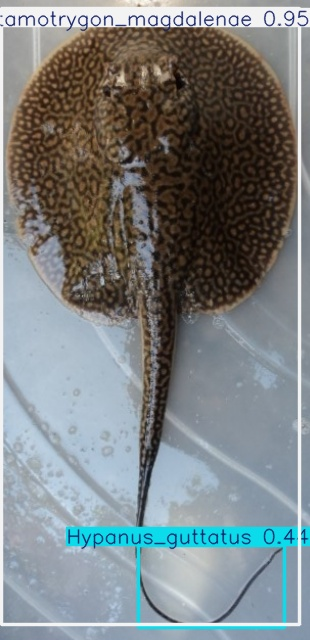

In [ ]:
from IPython.display import Image, display
display(Image(filename="/content/runs/detect/predict/Raya del magdalena.jpg"))

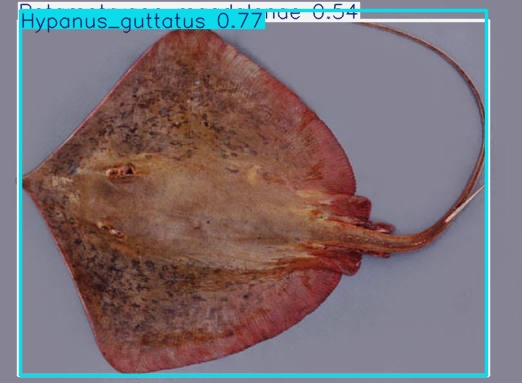

In [ ]:
from IPython.display import Image, display
display(Image(filename="/content/runs/detect/predict/Raya latigo 3.jpg"))

### Cargar el Modelo Final desde Google Drive
Utiliza las siguientes celdas para conectar tu Drive y cargar el modelo entrenado (`best.pt`) para tus nuevas pruebas.

In [ ]:
from google.colab import drive
from ultralytics import YOLO
from pathlib import Path

# 1. Montar Google Drive si no está montado
drive.mount('/content/drive')

# 2. Definir la ruta del modelo que guardaste en tu Drive
ruta_modelo_drive = Path("/content/drive/MyDrive/identimar/modelo_final_v1/best.pt")

# 3. Cargar el modelo en el nuevo entorno
if ruta_modelo_drive.exists():
    modelo_recuperado = YOLO(str(ruta_modelo_drive))
    print("¡Modelo cargado exitosamente desde Google Drive!")
    print(modelo_recuperado.info())
else:
    print(f"Error: No se encontró el archivo 'best.pt' en la ruta: {ruta_modelo_drive}")
    print("Verifica que la carpeta en tu Google Drive sea la correcta.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
¡Modelo cargado exitosamente desde Google Drive!
Model summary: 129 layers, 3,011,628 parameters, 0 gradients, 8.2 GFLOPs
(129, 3011628, 0, 8.1949184)


### Probar Nuevas Predicciones con el Modelo Recuperado
Utiliza la siguiente celda para procesar cualquier imagen de raya nueva y ver las detecciones hechas por tu modelo.


image 1/1 /content/identimar_api/identimar_api/externas/Raya latigo 5.jpg: 480x640 1 Hypanus_guttatus, 34.7ms
Speed: 2.1ms preprocess, 34.7ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)


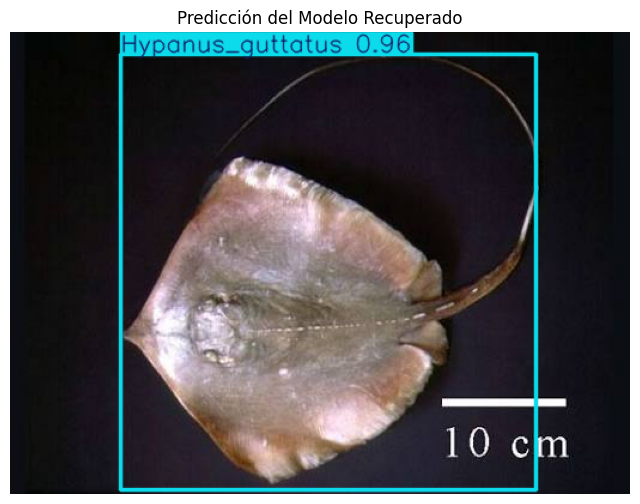

In [ ]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Coloca aquí la ruta de la imagen que quieres probar
# Puede ser un archivo en tu Drive, por ejemplo:
# ruta_imagen_prueba = "/content/drive/MyDrive/ruta/a/tu/nueva_raya.jpg"

# Para esta prueba usaremos una imagen existente de tu set de test de Roboflow
ruta_imagen_prueba = "/content/identimar_api/identimar_api/externas/Raya latigo 5.jpg"

if Path(ruta_imagen_prueba).exists():
    # 2. Ejecutar la predicción
    # Usamos conf=0.25 como umbral de confianza estándar
    resultados = modelo_recuperado.predict(source=ruta_imagen_prueba, conf=0.25, verbose=True)[0]

    # 3. Dibujar las cajas sobre la imagen y mostrar el resultado en Colab
    imagen_anotada = cv2.cvtColor(resultados.plot(), cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 8))
    plt.imshow(imagen_anotada)
    plt.axis("off")
    plt.title("Predicción del Modelo Recuperado")
    plt.show()
else:
    print(f"No se encontró ninguna imagen en: {ruta_imagen_prueba}")
    print("Por favor, cambia la variable 'ruta_imagen_prueba' por la ruta de un archivo real.")

In [ ]:
import importlib.util
import sys

# Ruta del archivo
file_path = "/content/cierre_modelo_final (1).py"
module_name = "cierre_modelo_final"

# Cargar el módulo dinámicamente
spec = importlib.util.spec_from_file_location(module_name, file_path)
cierre_modelo_final = importlib.util.module_from_spec(spec)
sys.modules[module_name] = cierre_modelo_final
spec.loader.exec_module(cierre_modelo_final)

print("¡Módulo 'cierre_modelo_final' importado exitosamente!")

¡Módulo 'cierre_modelo_final' importado exitosamente!


In [ ]:
from pathlib import Path

# Definir explícitamente la ruta correcta del entrenamiento
ruta_entrenamiento_real = Path("/content/runs/detect/identimar/baseline_n")

# Ejecutar el flujo completo pasando el modelo y su ruta de entrenamiento real
cierre_modelo_final.ejecutar_todo(modelo_base, run_dir=ruta_entrenamiento_real)

##### 1) Auditoría del dataset #####

[train] 876 imágenes | copias '_dup': 279 (anidadas: 0)
    Aetobatus_narinari           168 imágenes ( 19.2%)     180 instancias
    Hypanus_guttatus             168 imágenes ( 19.2%)     174 instancias
    Potamotrygon_magdalenae      372 imágenes ( 42.5%)     660 instancias
    Styracura_schmardae          168 imágenes ( 19.2%)     180 instancias

[valid] 58 imágenes | copias '_dup': 0 (anidadas: 0)
    Aetobatus_narinari            16 imágenes ( 27.6%)      16 instancias
    Hypanus_guttatus              17 imágenes ( 29.3%)      18 instancias
    Potamotrygon_magdalenae        9 imágenes ( 15.5%)       9 instancias
    Styracura_schmardae           16 imágenes ( 27.6%)      16 instancias

[test] 29 imágenes | copias '_dup': 0 (anidadas: 0)
    Aetobatus_narinari             8 imágenes ( 27.6%)       8 instancias
    Hypanus_guttatus               8 imágenes ( 27.6%)       8 instancias
    Potamotrygon_magdalenae        5 imágenes ( 17.2%)     

'/content/modelo_final_v1.zip'

In [ ]:
from google.colab import files

# Descargar el archivo consolidado del modelo final
files.download('/content/modelo_final_v1.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 1. Descomprimir la API y explorar el contenido

In [ ]:
import zipfile
import os

ruta_zip = "/content/identimar_api (2).zip"
destino_extraccion = "/content/identimar_api"

# Descomprimir el archivo
if os.path.exists(ruta_zip):
    with zipfile.ZipFile(ruta_zip, 'r') as zip_ref:
        zip_ref.extractall(destino_extraccion)
    print(f"¡Archivo descomprimido con éxito en: {destino_extraccion}!")

    # Listar los archivos extraídos
    print("\nArchivos encontrados en el proyecto:")
    for root, dirs, files in os.walk(destino_extraccion):
        for file in files:
            print(os.path.join(root, file))
else:
    print(f"No se encontró el archivo zip en la ruta: {ruta_zip}. Asegúrate de haberlo subido correctamente a la pestaña de archivos.")

¡Archivo descomprimido con éxito en: /content/identimar_api!

Archivos encontrados en el proyecto:
/content/identimar_api/identimar_api/identimar_api/requirements.txt
/content/identimar_api/identimar_api/identimar_api/docker-compose.yml
/content/identimar_api/identimar_api/identimar_api/README.md
/content/identimar_api/identimar_api/identimar_api/openapi.json
/content/identimar_api/identimar_api/identimar_api/.gitignore
/content/identimar_api/identimar_api/identimar_api/Dockerfile
/content/identimar_api/identimar_api/identimar_api/.dockerignore
/content/identimar_api/identimar_api/identimar_api/.env.example
/content/identimar_api/identimar_api/identimar_api/requirements-dev.txt
/content/identimar_api/identimar_api/identimar_api/tests/test_api.py
/content/identimar_api/identimar_api/identimar_api/tests/__init__.py
/content/identimar_api/identimar_api/identimar_api/feedback/.gitkeep
/content/identimar_api/identimar_api/identimar_api/models/.gitkeep
/content/identimar_api/identimar_api/id

### 2. Instalar dependencias adicionales de la API
Si tu API tiene un archivo `requirements.txt`, lo instalamos. Si está hecho con FastAPI/Uvicorn, instalamos los paquetes esenciales.

In [ ]:
# 1. Cambiar al directorio raíz correcto del proyecto (donde está el requirements.txt y la carpeta app/)
%cd /content/identimar_api/identimar_api/identimar_api/

# 2. Instalar todas las dependencias reales especificadas por tu API
import os
if os.path.exists("requirements.txt"):
    print("Instalando dependencias desde requirements.txt...")
    !pip install -r requirements.txt
else:
    !pip install fastapi uvicorn python-multipart

/content/identimar_api/identimar_api/identimar_api
Instalando dependencias desde requirements.txt...


### 2.5 Copiar el Modelo Entrenado a la Carpeta de la API
Este paso copia tus mejores pesos `best.pt` desde Google Drive a la carpeta interna de modelos de la API para solucionar el error de archivo no encontrado.

In [ ]:
import shutil
from pathlib import Path

# Ruta origen de tus pesos en Google Drive
origen_modelo = Path("/content/drive/MyDrive/identimar/modelo_final_v1/best.pt")

# Ruta destino que espera la API dentro de su estructura
destino_modelo = Path("/content/identimar_api/identimar_api/identimar_api/models/best.pt")

# Asegurar que la carpeta destino existe
destino_modelo.parent.mkdir(parents=True, exist_ok=True)

# Copiar el archivo
if origen_modelo.exists():
    shutil.copy(origen_modelo, destino_modelo)
    print(f"¡Éxito! El modelo fue copiado correctamente a: {destino_modelo}")
else:
    print(f"Error: No se encontró el archivo de origen en: {origen_modelo}")
    print("Por favor, verifica que tu Google Drive esté montado y que el archivo exista en esa ruta.")

¡Éxito! El modelo fue copiado correctamente a: /content/identimar_api/identimar_api/identimar_api/models/best.pt


In [ ]:
import os
from pathlib import Path

# Ruta real donde copiamos el modelo anteriormente
ruta_modelo_real = Path("/content/identimar_api/identimar_api/identimar_api/models/best.pt")

# Crear la carpeta /models en la raíz del sistema (/) si no existe
os.makedirs("/models", exist_ok=True)

# Definir el destino requerido por la API
destino_absoluto = Path("/models/best.pt")

# Si ya existe un archivo o enlace previo, removerlo para evitar conflictos
if destino_absoluto.exists() or destino_absoluto.is_symlink():
    if destino_absoluto.is_symlink():
        destino_absoluto.unlink()
    else:
        os.remove(destino_absoluto)

# Crear enlace simbólico desde la raíz /models/best.pt apuntando a la ruta real
if ruta_modelo_real.exists():
    os.symlink(str(ruta_modelo_real), str(destino_absoluto))
    print("¡Éxito! Se ha enlazado el modelo correctamente a la raíz esperada por la API: /models/best.pt")
else:
    print(f"Error: Asegúrate de haber ejecutado la celda anterior para copiar el modelo a {ruta_modelo_real}")

¡Éxito! Se ha enlazado el modelo correctamente a la raíz esperada por la API: /models/best.pt


### 3. Ejecutar la API en segundo plano con un túnel público
Dado que Colab se ejecuta en servidores de Google, no podemos acceder a `localhost:8000` directamente desde nuestro navegador. Usaremos `pyngrok` o `localtunnel` para generar un enlace público y poder hacerle peticiones a tu API.

*Nota: Ajusta el nombre del archivo (ej. `app:app` o `main:app`) en el comando de uvicorn según corresponda con el archivo principal que se listó en el paso 1.*

In [ ]:
# Asegurarnos de que estamos en la ubicación correcta
%cd /content/identimar_api/identimar_api/identimar_api/

# Instalar localtunnel para exponer la API públicamente
!npm install -g localtunnel

import subprocess
import time

# 1. Iniciar localtunnel en segundo plano para el puerto 8000
print("Iniciando túnel público de Localtunnel...")
process_lt = subprocess.Popen(["lt", "--port", "8000"], stdout=subprocess.PIPE)
time.sleep(3) # Esperar a que se asigne la URL pública

# Leer y mostrar la URL pública generada
for line in iter(process_lt.stdout.readline, b''):
    line_decoded = line.decode('utf-8')
    if "your url is:" in line_decoded:
        print("\n=========================================")
        print(f"ACCEDE A TU API DESDE ESTE ENLACE:\n{line_decoded.strip()}")
        print("=========================================\n")
        break

# 2. Iniciar el servidor de la API en SEGUNDO PLANO
print("Iniciando el servidor de la API en segundo plano...")
# subprocess.Popen inicia el comando sin bloquear la celda de Colab
process_api = subprocess.Popen(
    ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "8000"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(3) # Esperar un momento a que inicialice
print("¡Listo! El servidor se está ejecutando en segundo plano.")
print("La celda ha finalizado, ahora puedes ejecutar libremente el script de pruebas.")

/content/identimar_api/identimar_api/identimar_api
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴
changed 22 packages in 2s
⠴
⠴3 packages are looking for funding
⠴  run `npm fund` for details
⠴Iniciando túnel público de Localtunnel...

ACCEDE A TU API DESDE ESTE ENLACE:
your url is: https://ripe-ways-eat.loca.lt

Iniciando el servidor de la API en segundo plano...
¡Listo! El servidor se está ejecutando en segundo plano.
La celda ha finalizado, ahora puedes ejecutar libremente el script de pruebas.


In [ ]:
import requests
import json
from pathlib import Path

# 1. Configurar URL de la API
API_URL = "http://localhost:8000/predict"

# 2. Ruta de la imagen de prueba
ruta_imagen = "/content/drive/MyDrive/IdentiMar/Externas/chupare 2.jpg"

if Path(ruta_imagen).exists():
    print(f"Enviando {Path(ruta_imagen).name} con el formato requerido por la API...")

    # Preparar los bytes del archivo usando el campo obligatorio 'imagen'
    with open(ruta_imagen, "rb") as file_bytes:
        files = {
            "imagen": (Path(ruta_imagen).name, file_bytes, "image/jpeg")
        }
        # Datos obligatorios adicionales solicitados por el body del endpoint
        data = {
            "id_observacion": "obs_prueba_colab_01"
        }

        try:
            # Realizar la petición POST enviando tanto 'data' como 'files'
            response = requests.post(API_URL, data=data, files=files)

            # Mostrar los resultados detallados
            if response.status_code == 200:
                print("\n¡Petición Exitosa! Respuesta estructurada de la API:")
                print(json.dumps(response.json(), indent=4, ensure_ascii=False))
            else:
                print(f"\nError en la petición (Código {response.status_code}):")
                try:
                    print(json.dumps(response.json(), indent=4, ensure_ascii=False))
                except:
                    print(response.text)

        except requests.exceptions.ConnectionError:
            print("\nError: No se pudo conectar con la API. Verifica que la celda anterior siga activa.")
else:
    print(f"Error: No se encontró la imagen en {ruta_imagen}")

Enviando chupare 2.jpg con el formato requerido por la API...

¡Petición Exitosa! Respuesta estructurada de la API:
{
    "id_observacion": "obs_prueba_colab_01",
    "especie_propuesta": "Styracura_schmardae",
    "confianza": 0.9423,
    "umbral_minimo": 0.7,
    "estado": "identificado"
}


In [ ]:
import os
import sys

# Asegurar que la ruta de entrenamiento de la carpeta extraída esté en el path
ruta_entrenamiento = '/content/identimar_vision_extracted/identimar-vision/entrenamiento'
if ruta_entrenamiento not in sys.path:
    sys.path.append(ruta_entrenamiento)

print("Archivos disponibles para verificar en el directorio de entrenamiento:")
for f in os.listdir(ruta_entrenamiento):
    if f.endswith('.py') or f.endswith('.md'):
        print(f" - {f}")

# Intentar buscar e importar funciones de auditoría si existen en 'cierre_modelo_final'
try:
    import cierre_modelo_final
    print("\nMódulo 'cierre_modelo_final' cargado con éxito.")
    # Si existe una función de auditoría específica expuesta, la listamos
    attrs = [attr for attr in dir(cierre_modelo_final) if 'auditar' in attr.lower() or 'duplicado' in attr.lower()]
    if attrs:
        print(f"Funciones de auditoría encontradas: {attrs}")
except Exception as e:
    print(f"\nNo se pudo importar automáticamente el módulo de cierre: {e}")

Archivos disponibles para verificar en el directorio de entrenamiento:
 - LEEME.md
 - cierre_modelo_final.py
 - contrato_salida.py
 - sobremuestreo_idempotente.py

Módulo 'cierre_modelo_final' cargado con éxito.
Funciones de auditoría encontradas: ['auditar_particion']


In [ ]:
import os
import zipfile
import hashlib

# 1. Descomprimir el archivo zip de Pruebas
ruta_pruebas_zip = '/content/Pruebas-20261026T170148Z-1-001.zip'
destino_pruebas = '/content/pruebas_2026_extracted'

if os.path.exists(ruta_pruebas_zip):
    with zipfile.ZipFile(ruta_pruebas_zip, 'r') as zip_ref:
        zip_ref.extractall(destino_pruebas)
    print(f"¡Éxito! Archivo de pruebas extraído en: {destino_pruebas}")
else:
    print(f"Error: No se encontró el archivo {ruta_pruebas_zip}")

# 2. Función para calcular el hash MD5 de un archivo (para detectar duplicados exactos)
def calcular_md5(ruta_archivo):
    hash_md5 = hashlib.md5()
    with open(ruta_archivo, "rb") as f:
        for chunk in iter(lambda: f.read(4096), b""):
            hash_md5.update(chunk)
    return hash_md5.hexdigest()

# 3. Mapear los hashes de las imágenes del dataset original
ruta_dataset = '/content/IdentiMar-Rayas-2'
hashes_dataset = {}

for root, dirs, files in os.walk(ruta_dataset):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
            ruta_completa = os.path.join(root, file)
            # Obtener si es train, valid o test de la ruta
            categoria = 'desconocido'
            if 'train' in root: categoria = 'train'
            elif 'valid' in root: categoria = 'valid'
            elif 'test' in root: categoria = 'test'

            try:
                h = calcular_md5(ruta_completa)
                hashes_dataset[h] = (file, categoria, ruta_completa)
            except Exception as e:
                pass

print(f"Hashes del dataset base calculados: {len(hashes_dataset)} imágenes registradas.")

# 4. Comparar las imágenes de pruebas para encontrar duplicados
duplicados_encontrados = []

for root, dirs, files in os.walk(destino_pruebas):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
            ruta_completa = os.path.join(root, file)
            try:
                h = calcular_md5(ruta_completa)
                if h in hashes_dataset:
                    nombre_orig, cat_orig, ruta_orig = hashes_dataset[h]
                    duplicados_encontrados.append({
                        'imagen_prueba': file,
                        'ruta_prueba': ruta_completa,
                        'duplicado_de': nombre_orig,
                        'categoria_dataset': cat_orig,
                        'ruta_dataset': ruta_orig
                    })
            except Exception as e:
                pass

print(f"\n--- RESULTADOS DE DUPLICADOS ({len(duplicados_encontrados)} encontrados) ---")
if duplicados_encontrados:
    for dup in duplicados_encontrados:
        print(f"Imagen de prueba '{dup['imagen_prueba']}' es duplicado exacto de '{dup['duplicado_de']}' en [{dup['categoria_dataset']}]")
else:
    print("¡Excelente! No se encontraron imágenes duplicadas entre las pruebas del zip y el dataset de entrenamiento, validación o test.")

¡Éxito! Archivo de pruebas extraído en: /content/pruebas_2026_extracted
Hashes del dataset base calculados: 684 imágenes registradas.

--- RESULTADOS DE DUPLICADOS (0 encontrados) ---
¡Excelente! No se encontraron imágenes duplicadas entre las pruebas del zip y el dataset de entrenamiento, validación o test.
